Connected to festim-env (Python 3.14.2)

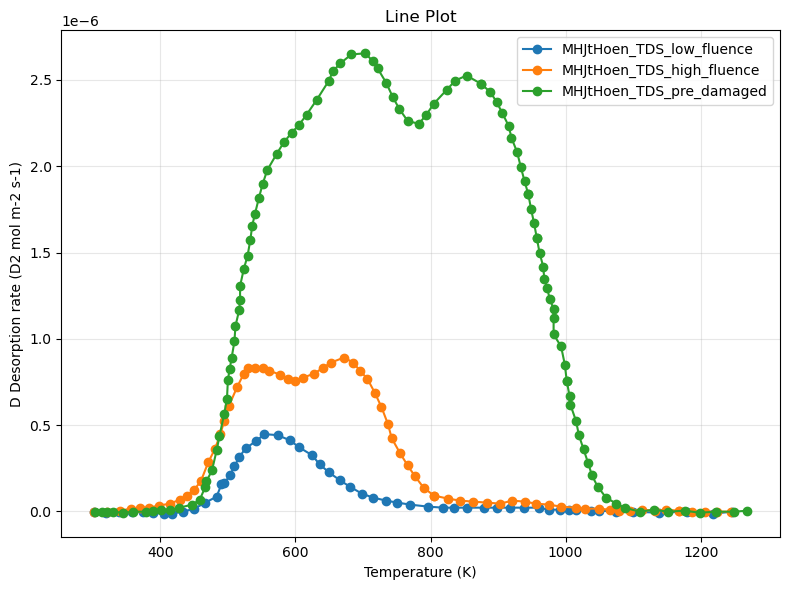

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Three CSV files in the working directory, low, high fluence, and a pre-damaged spectra. Units are in temperature (K) and D desorption rate in 10^14 D2/s

colnames = ['T', 'Desorption_rate']

low_TDS =  pd.read_csv("MHJtHoen_TDS_low_fluence.csv", names=colnames, header=None)
high_TDS = pd.read_csv("MHJtHoen_TDS_high_fluence.csv",names=colnames, header=None)
predam_TDS =  pd.read_csv("MHJtHoen_TDS_pre_damaged.csv", names=colnames, header=None)

# This paper reports desorption rate in terms of 10^14 molecules of D2 s-1, whereas FESTIM calculates mol m-2 s-1. So we convert.

a_cm2 = 1.7 # sample surface area in cm^-2
a_m2 = a_cm2/np.square(100) # in m2

low_TDS['Desorption_rate'] = (low_TDS['Desorption_rate']/a_m2)*(1e14/6.022e23)
high_TDS['Desorption_rate'] = (high_TDS['Desorption_rate']/a_m2)*(1e14/6.022e23)
predam_TDS['Desorption_rate'] = (predam_TDS['Desorption_rate']/a_m2)*(1e14/6.022e23)

fig, ax = plt.subplots(figsize=(8, 6))

# Line plot for each dataframe
ax.plot(low_TDS['T'], low_TDS['Desorption_rate'], label='MHJtHoen_TDS_low_fluence', marker='o')
ax.plot(high_TDS['T'], high_TDS['Desorption_rate'], label='MHJtHoen_TDS_high_fluence', marker='o')
ax.plot(predam_TDS['T'], predam_TDS['Desorption_rate'], label='MHJtHoen_TDS_pre_damaged', marker='o')

ax.set_xlabel('Temperature (K)')
ax.set_ylabel('D Desorption rate (D2 mol m-2 s-1)')
ax.set_title('Line Plot')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## RustBCA python binding example

In [ ]:
from libRustBCA import *
import numpy as np
import matplotlib.pyplot as plt

# Recreates 100eV_H_in_W.toml using libRustBCA's compound_bca_list_1D_py instead
# of writing a TOML file and calling the RustBCA binary. Values are taken
# directly from the TOML (not from scripts/materials.py defaults, which differ
# slightly, e.g. Es_H = 1.5 eV there vs 0.0 eV in this TOML).
#
# Note: compound_bca_list_1D_py doesn't expose everything the TOML does -
# displacement energies (Ed = [25, 25]), electronic_stopping_correction_factors,
# and the surface/bulk binding models (PLANAR/AVERAGE) are fixed internally and
# can't be set through this binding.

# --- particle_parameters: 1000 x 100 eV H ---
N = 1000
energy_eV = 100.0
Z1_H, m1_H = 1.0, 1.008   # Z, m
Ec1_H, Es1_H = 1.0, 0.0   # Ec, Es

# dir = [0.999, 0.001, 0.0] in the TOML -> normalize to a unit vector
dir_vec = np.array([0.999, 0.001, 0.0])
dir_vec /= np.linalg.norm(dir_vec)

ux = [dir_vec[0]] * N
uy = [dir_vec[1]] * N
uz = [dir_vec[2]] * N
energies = [energy_eV] * N
Z1 = [Z1_H] * N
m1 = [m1_H] * N
Ec1 = [Ec1_H] * N
Es1 = [Es1_H] * N

# --- material_parameters: species 0 = Ti, species 1 = W ---
Z2 = [22.0, 74.0]
m2 = [47.867, 183.84]
Ec2 = [3.5, 1.0]
Es2 = [4.89, 8.68]
Eb2 = [3.0, 3.0]

# --- geometry_input: 2-layer target, densities given per micron^3 in the TOML ---
# layer 0: ~1 A Ti skin, layer 1: 50 micron W bulk
A_PER_MICRON = 1e4
densities_per_micron3 = [[5.664e10, 0.0], [0.0, 6.322e10]]
layer_thicknesses_micron = [0.0001, 50.0]

# convert to what the binding expects: densities in 1/Angstrom^3, thicknesses in Angstrom
n2 = [[n / A_PER_MICRON**3 for n in layer] for layer in densities_per_micron3]
dx = [t * A_PER_MICRON for t in layer_thicknesses_micron]

output, incident, stopped = compound_bca_list_1D_py(
    ux, uy, uz, energies, Z1, m1, Ec1, Es1, Z2, m2, Ec2, Es2, Eb2, n2, dx
)

output = np.array(output)
incident = np.array(incident)
stopped = np.array(stopped)

# output columns: [Z, m, E (eV), x, y, z (A), ux, uy, uz]
reflected = incident & ~stopped   # incident H that left back out the front
implanted = incident & stopped    # incident H that came to rest in the target
sputtered = ~incident & ~stopped  # target recoils (Ti/W) that escaped

print(f'{N} x {energy_eV} eV H -> Ti/W layered target')
print(f'Reflected: {reflected.sum()} ({reflected.sum()/N:.3f})')
print(f'Implanted: {implanted.sum()} ({implanted.sum()/N:.3f})')
print(f'Sputtered: {sputtered.sum()} ({sputtered.sum()/N:.3f})')

implanted_depth_A = output[implanted, 3]
plt.figure(figsize=(8, 5))
plt.hist(implanted_depth_A, bins=50, histtype='step')
plt.xlabel('Implantation depth [A]')
plt.ylabel('Counts')
plt.title(f'Implanted H depth distribution ({energy_eV} eV)')
plt.show()

No kernel connected

No kernel connected